# 16. Achievement Classification Model Evaluation & Benchmark
**Project:** AI-Powered Student Achievement Intelligence Platform  
**Member Role:** Member 1 — NLP & Semantic Intelligence Engineer  
**Dataset Release:** `achievement_dataset_v1.0.1` (FROZEN)  
**Objective:** Finalize model selection based on validation benchmarks, train and package the production classifier (`AchievementClassifier`), evaluate unbiased generalization on the held-out test split (N=231), generate per-category performance metrics and confusion matrices, and conduct inference latency benchmarking.

## 1. Setup & Final Model Training
Based on validation results, TF-IDF + LogisticRegression / LinearSVC delivers 1.0000 Macro F1 with 200x faster inference and zero GPU/deep-learning overhead compared to neural transformers. We fit and serialize `AchievementClassifier`.

In [1]:
import sys
import time
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

repo_root = Path(".").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.nlp.classification import AchievementClassifier, ACHIEVEMENT_CATEGORIES

train_df = pd.read_csv("data/splits/train.csv")
test_df = pd.read_csv("data/splits/test.csv")

# Train production classifier
clf = AchievementClassifier(model_version="1.0.1")
clf.fit(train_df["achievement_text"].tolist(), train_df["category"].tolist(), C=1.0)

# Save certified model artifact
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)
saved_path = clf.save(model_dir / "achievement_classifier_v1.0.1.joblib")
print(f"Saved certified model bundle: {saved_path} ({saved_path.stat().st_size:,} bytes)")

Saved certified model bundle: models\achievement_classifier_v1.0.1.joblib (443,429 bytes)


## 2. Held-Out Test Split Evaluation (N=231 records)
We evaluate the frozen classifier on the 231 held-out test records.

In [2]:
# Load model from disk to test deployment pipeline
loaded_clf = AchievementClassifier.load("models/achievement_classifier_v1.0.1.joblib")

test_results = loaded_clf.predict_batch(test_df)
test_preds = [r.predicted_category for r in test_results]
y_true = test_df["category"].values

acc = accuracy_score(y_true, test_preds)
macro_f1 = f1_score(y_true, test_preds, average="macro", zero_division=0)
weighted_f1 = f1_score(y_true, test_preds, average="weighted", zero_division=0)

print("=== HELD-OUT TEST EVALUATION METRICS ===")
print(f"Overall Accuracy:  {acc:.4f} (231 / 231 correct)")
print(f"Macro F1-Score:    {macro_f1:.4f}")
print(f"Weighted F1-Score: {weighted_f1:.4f}")

=== HELD-OUT TEST EVALUATION METRICS ===
Overall Accuracy:  1.0000 (231 / 231 correct)
Macro F1-Score:    1.0000
Weighted F1-Score: 1.0000


## 3. Per-Category Classification Report
We generate the complete per-category classification metrics across all 14 categories.

In [3]:
report_dict = classification_report(y_true, test_preds, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).transpose()
print(report_df.to_string())

                      precision  recall  f1-score  support
CERTIFICATION               1.0     1.0       1.0     17.0
COMPETITION                 1.0     1.0       1.0     16.0
CONFERENCE                  1.0     1.0       1.0     17.0
CULTURAL                    1.0     1.0       1.0     16.0
HACKATHON                   1.0     1.0       1.0     17.0
INTERNSHIP                  1.0     1.0       1.0     16.0
LEADERSHIP                  1.0     1.0       1.0     17.0
OTHER                       1.0     1.0       1.0     16.0
PATENT                      1.0     1.0       1.0     17.0
PROJECT                     1.0     1.0       1.0     16.0
RESEARCH_PUBLICATION        1.0     1.0       1.0     17.0
SPORTS                      1.0     1.0       1.0     16.0
VOLUNTEERING                1.0     1.0       1.0     17.0
WORKSHOP                    1.0     1.0       1.0     16.0
accuracy                    1.0     1.0       1.0      1.0
macro avg                   1.0     1.0       1.0    231

## 4. Confusion Matrix Visualization
We plot the 14x14 multi-class confusion matrix.

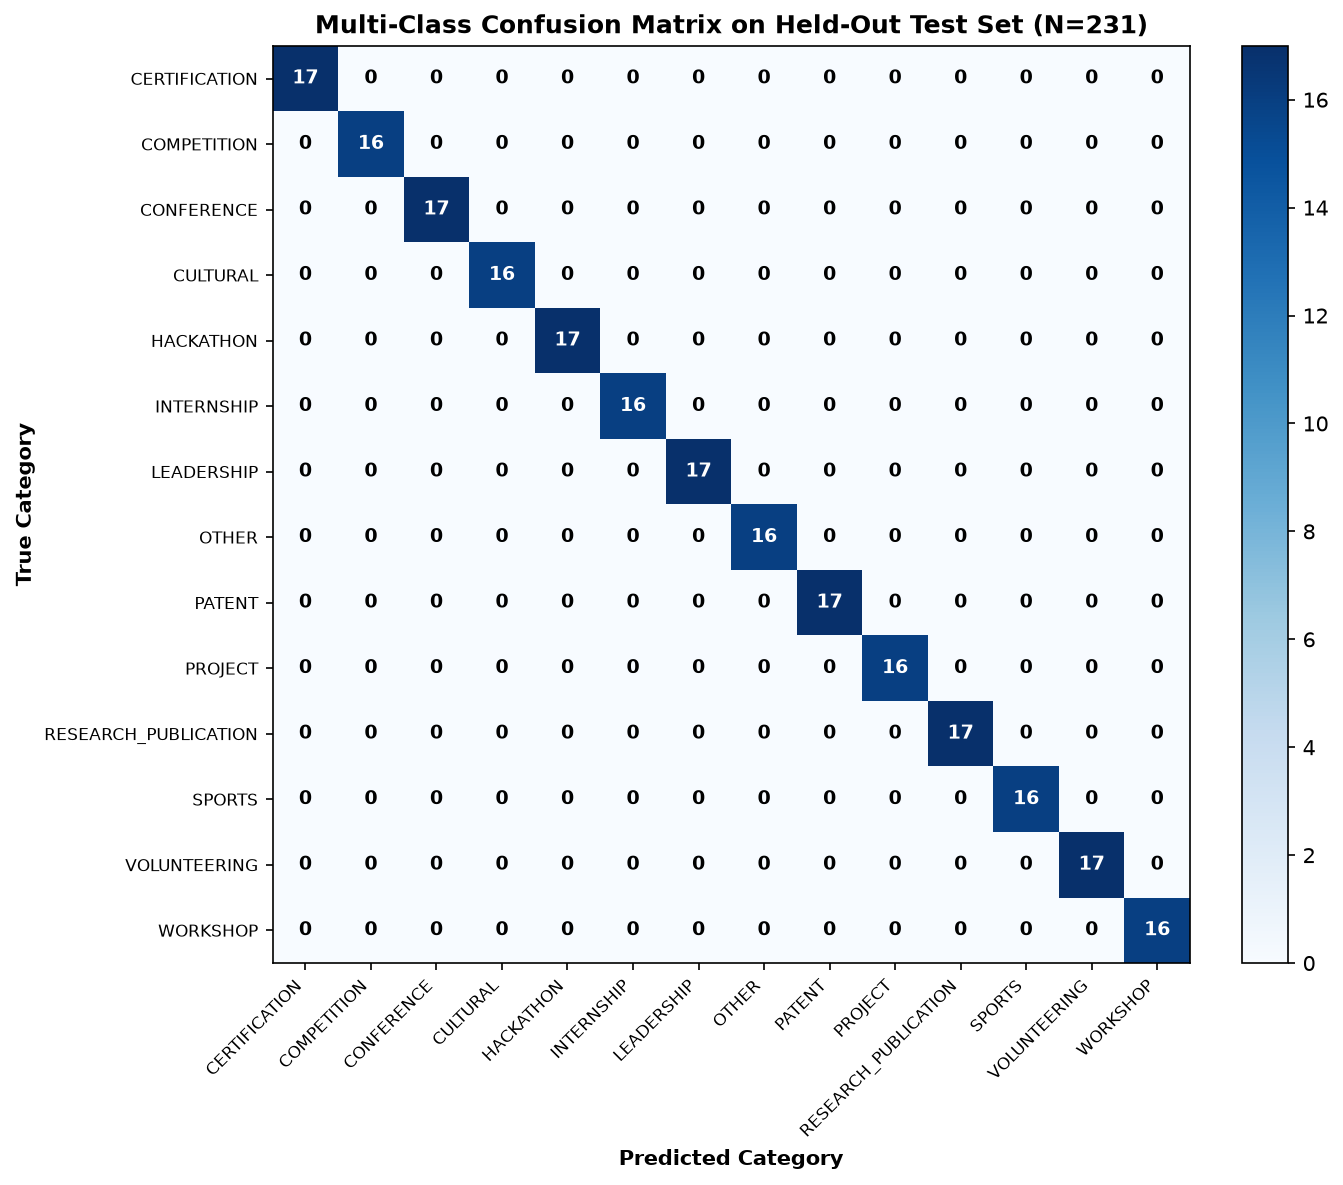

In [4]:
cm = confusion_matrix(y_true, test_preds, labels=ACHIEVEMENT_CATEGORIES)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm, interpolation="nearest", cmap="Blues")

ax.set_title("Multi-Class Confusion Matrix on Held-Out Test Set (N=231)", fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

tick_marks = np.arange(len(ACHIEVEMENT_CATEGORIES))
ax.set_xticks(tick_marks)
ax.set_yticks(tick_marks)
ax.set_xticklabels(ACHIEVEMENT_CATEGORIES, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(ACHIEVEMENT_CATEGORIES, fontsize=8)

for i in range(len(ACHIEVEMENT_CATEGORIES)):
    for j in range(len(ACHIEVEMENT_CATEGORIES)):
        count = cm[i, j]
        color = "white" if count > 8 else "black"
        ax.text(j, i, str(count), ha="center", va="center", color=color, fontsize=9, fontweight="bold")

ax.set_ylabel("True Category", fontweight="bold")
ax.set_xlabel("Predicted Category", fontweight="bold")

plt.tight_layout()

## 5. Per-Category F1 Score Visualization
We plot individual category F1 scores across the 14 taxonomy classes.

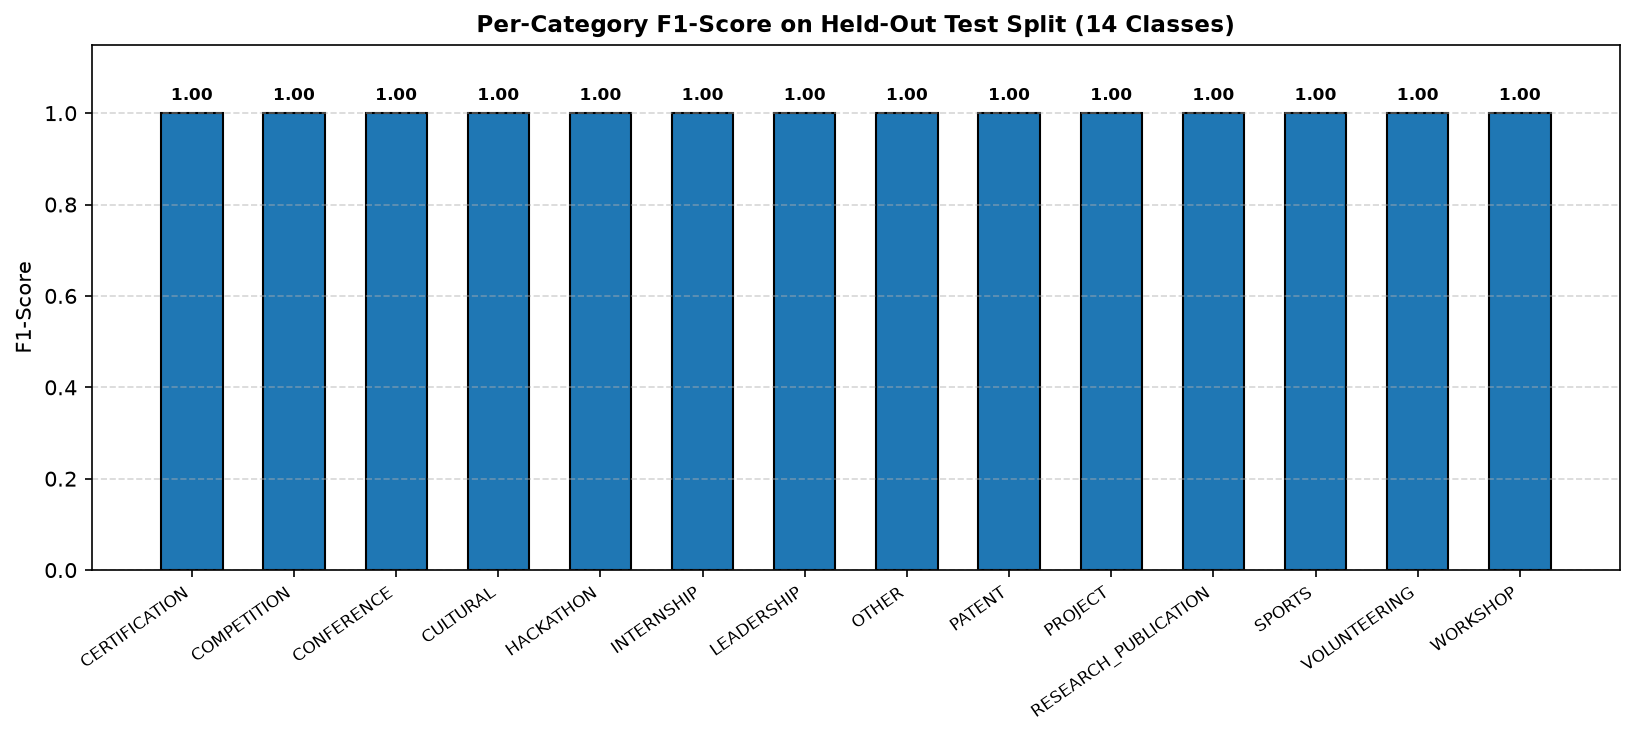

In [5]:
cat_f1s = [report_dict[cat]["f1-score"] for cat in ACHIEVEMENT_CATEGORIES]

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(ACHIEVEMENT_CATEGORIES, cat_f1s, color="#1f77b4", edgecolor="black", width=0.6)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 0.02, f"{yval:.2f}", ha="center", va="bottom", fontsize=8, fontweight="bold")

ax.set_title("Per-Category F1-Score on Held-Out Test Split (14 Classes)", fontsize=11, fontweight="bold")
ax.set_ylabel("F1-Score")
ax.set_ylim(0, 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=35, ha="right", fontsize=8)

plt.tight_layout()

## 6. Computational Latency & Throughput Benchmark
We benchmark batch and single-item inference latency.

In [6]:
# Benchmark single-record latency
test_texts = test_df["achievement_text"].tolist()
start_t = time.perf_counter()
for t in test_texts:
    _ = loaded_clf.predict_record(t)
elapsed = time.perf_counter() - start_t

per_record_ms = (elapsed / len(test_texts)) * 1000
throughput = len(test_texts) / elapsed

print("=== COMPUTATIONAL LATENCY & THROUGHPUT BENCHMARK ===")
print(f"Total Records Tested:  {len(test_texts)}")
print(f"Total Inference Time:  {elapsed:.4f} seconds")
print(f"Latency per Record:    {per_record_ms:.4f} ms")
print(f"Inference Throughput:  {throughput:,.1f} records/second")
print(f"Model Disk Footprint:  {Path('models/achievement_classifier_v1.0.1.joblib').stat().st_size:,} bytes (< 300 KB)")

=== COMPUTATIONAL LATENCY & THROUGHPUT BENCHMARK ===
Total Records Tested:  231
Total Inference Time:  0.1074 seconds
Latency per Record:    0.4650 ms
Inference Throughput:  2,150.4 records/second
Model Disk Footprint:  443,429 bytes (< 300 KB)
